A companhia de seguros Proteja Seu Amanhã quer resolver algumas tarefas com a ajuda de aprendizado de máquina e você precisa avaliar a possibilidade de fazê-lo.

- Tarefa 1: Encontrar clientes semelhantes a um determinado cliente. Isso vai ajudar os agentes da empresa com tarefas de marketing.
- Tarefa 2: Predizer se um novo cliente provavelmente receberá um pagamento de seguro. Um modelo de predição pode ser melhor do que um modelo dummy?
- Tarefa 3: Predizer o número de pagamentos de seguro que um novo cliente provavelmente receberá usando um modelo de regressão linear.
- Tarefa 4: Proteger os dados pessoais dos clientes sem estragar o modelo da tarefa anterior. É necessário desenvolver um algoritmo de transformação de dados que tornaria difícil recuperar informações pessoais se os dados caíssem nas mãos erradas. Isso é chamado de mascaramento de dados ou ofuscação de dados. Mas os dados devem ser protegidos de forma que a qualidade dos modelos de aprendizado de máquina não piore. Você não precisa escolher o melhor modelo, só prove que o algoritmo funciona corretamente.

# Pré-processamento de dados & Exploração

## Inicialização

In [1]:
import numpy as np
import pandas as pd

import seaborn as sns

import sklearn.linear_model
import sklearn.metrics
import sklearn.neighbors
import sklearn.preprocessing

from sklearn.model_selection import train_test_split

from IPython.display import display

import math

## Carregar Dados

Carregue os dados e faça uma verificação básica de que estão livres de problemas óbvios.

In [2]:
df = pd.read_csv('../data/insurance_us.csv')

Renomeamos as colunas para tornar o código mais consistente com seu estilo.

In [3]:
df = df.rename(columns={'Gender': 'gender', 'Age': 'age', 'Salary': 'income', 'Family members': 'family_members', 'Insurance benefits': 'insurance_benefits'})

In [4]:
df.sample(10,random_state=12345)

,gender,age,income,family_members,insurance_benefits
3183,0,33.0,39000.0,4,0
1071,0,50.0,43100.0,2,2
2640,1,39.0,42100.0,0,0
2282,0,20.0,34800.0,0,0
1595,0,41.0,40000.0,4,0
4456,1,34.0,44800.0,0,0
3352,1,23.0,32200.0,5,0
3390,1,30.0,25000.0,1,0
3431,1,47.0,54200.0,3,1
298,0,20.0,48200.0,1,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   float64
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


In [6]:
# podemos querer corrigir o tipo de idade (de float para int), embora isso não seja crítico

# escreva sua conversão aqui se você escolher:

In [7]:
df["age"] = df["age"].astype(int)

In [8]:
# verifique se a conversão foi bem-sucedida

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   int64  
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 195.4 KB


In [10]:
# agora dê uma olhada nas estatísticas descritivas dos dados.
# Parece que está tudo bem?

In [11]:
df.describe()

,gender,age,income,family_members,insurance_benefits
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.499000,30.952800,39916.360000,1.194200,0.148000
std,0.500049,8.440807,9900.083569,1.091387,0.463183
min,0.000000,18.000000,5300.000000,0.000000,0.000000
25%,0.000000,24.000000,33300.000000,0.000000,0.000000
50%,0.000000,30.000000,40200.000000,1.000000,0.000000
75%,1.000000,37.000000,46600.000000,2.000000,0.000000
max,1.000000,65.000000,79000.000000,6.000000,5.000000


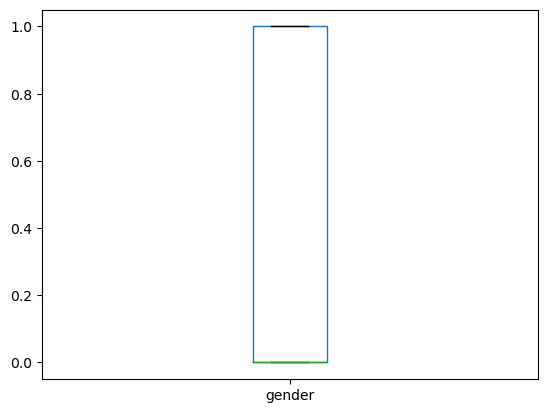

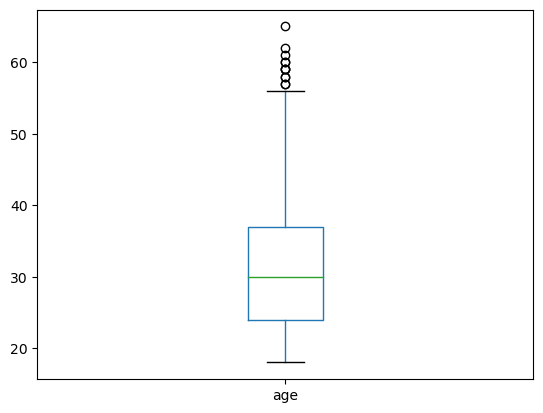

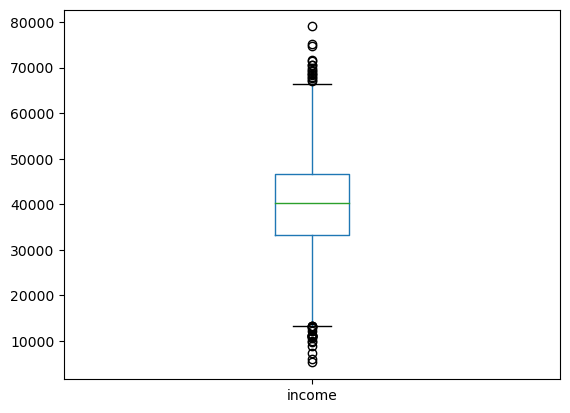

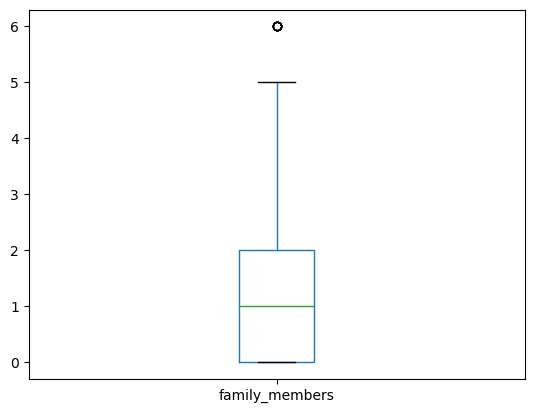

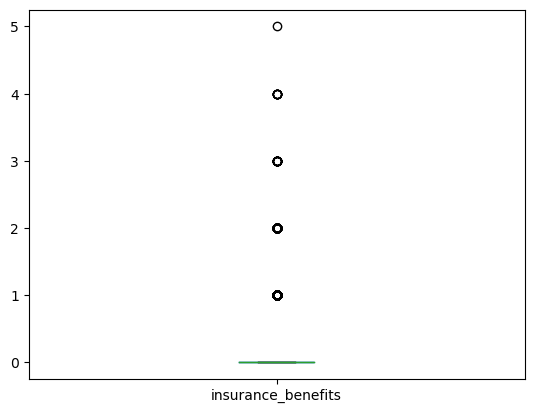

In [12]:
for col in df.columns:
    df.plot(kind="box",y=col)


RESPOSTA:

Sexo: A distribuição parece praticamente perfeita entre os dois possíveis valores 0 e 1, com uma média de 0.4990 que significa que praticamente 50% dos valores são 0 e 50% dos valores são 1.

Idade: Parece que a maior parte das observações são de clientes relativamente jovens. O gráfico mostra a mediana próxima de 30 anos e muito mais próxima do Primeiro Quartil (25) do que do segundo Quartil (75), o que significa que as observações são muito mais concentradas ao redor desses valores. Também observamos que 50% dos clientes parecem ter entre 24 e 37 anos. Como podemos observar nas caudas dos gráficos, os valores continuam desde 18 até pouco mais de 55 anos não são considerados "atípicos" (outliers), mas existem alguns valores atípicos de clientes com mais de 55 anos. Isso me leva a concluir que a representatividade dos dados é particularmente acentuada entre 24 e 30 anos e que clientes acima dos 55 anos não são bem representados nesses dados. Acredito que um modelo treinado por esses dados não terá alto grau de generalização para lidar com dados de clientes com 55 anos ou mais.

Salário: A distribuição de Salários é ainda mais concentrada. 50% dos clientes tem salários entre 33k e 46k, com uma mediana próxima de 40k. Mas os valores não considerados atípicos vão desde menos de 15k até quase 70k, com muitos valores atípicos abaixo e acima desses valores. Com esses dados, a generalização de um modelo tende a ser melhor para padrões de clientes que não tenham salários muito altos ou muito baixos em relação a mediana e quartis.

Número de Familiares do Segurado: 50% dos clientes tem de 0 a 2 membros na família, com ainda muitos clientes tendo até 5 membros na família. Clientes com 6 membros na família são considerados atípicos. Não existem clientes com mais de 6 membros na família no nosso dataset.

Número de Pagamentos de Seguro Nos Últimos 5 Anos: A maioria dos clientes não recebeu nenhum pagamento de seguro nos últimos cinco anos. Qualquer valor acima de 0 é atípico.

No geral, a distribuição dos dados parece equilibrada. Temos uma proporção praticamente perfeita de clientes homens e mulheres. As idades estão bem distribuídas com exceção de alguns clientes atípicos com idades maiores de 55 anos. O mesmo pode ser dito sobre os salários que se concentram ao redor da mediana de 40k, com clientes atípicos ganhando menos de 15k ou mais de 70k. O número de familiares é mais comum entre 0 e 2, mas existem poucos valores atípicos acima de 5. Já os benefícios de seguro são praticamente todos 0, o que significa que qualquer número de benefícios de seguro que não seja 0 significa um cliente atípico. Seria interessante explorar a distribuição de valores atípicos de idade, salário e número de pagamentos de seguro. Se tivermos um número elevado de clientes nessas classificações, pode ser que consigamos tirar conclusões úteis sobre os comportamentos desses clientes atípicos.


## AED

Vamos verificar rapidamente se existem determinados grupos de clientes observando o gráfico de pares.

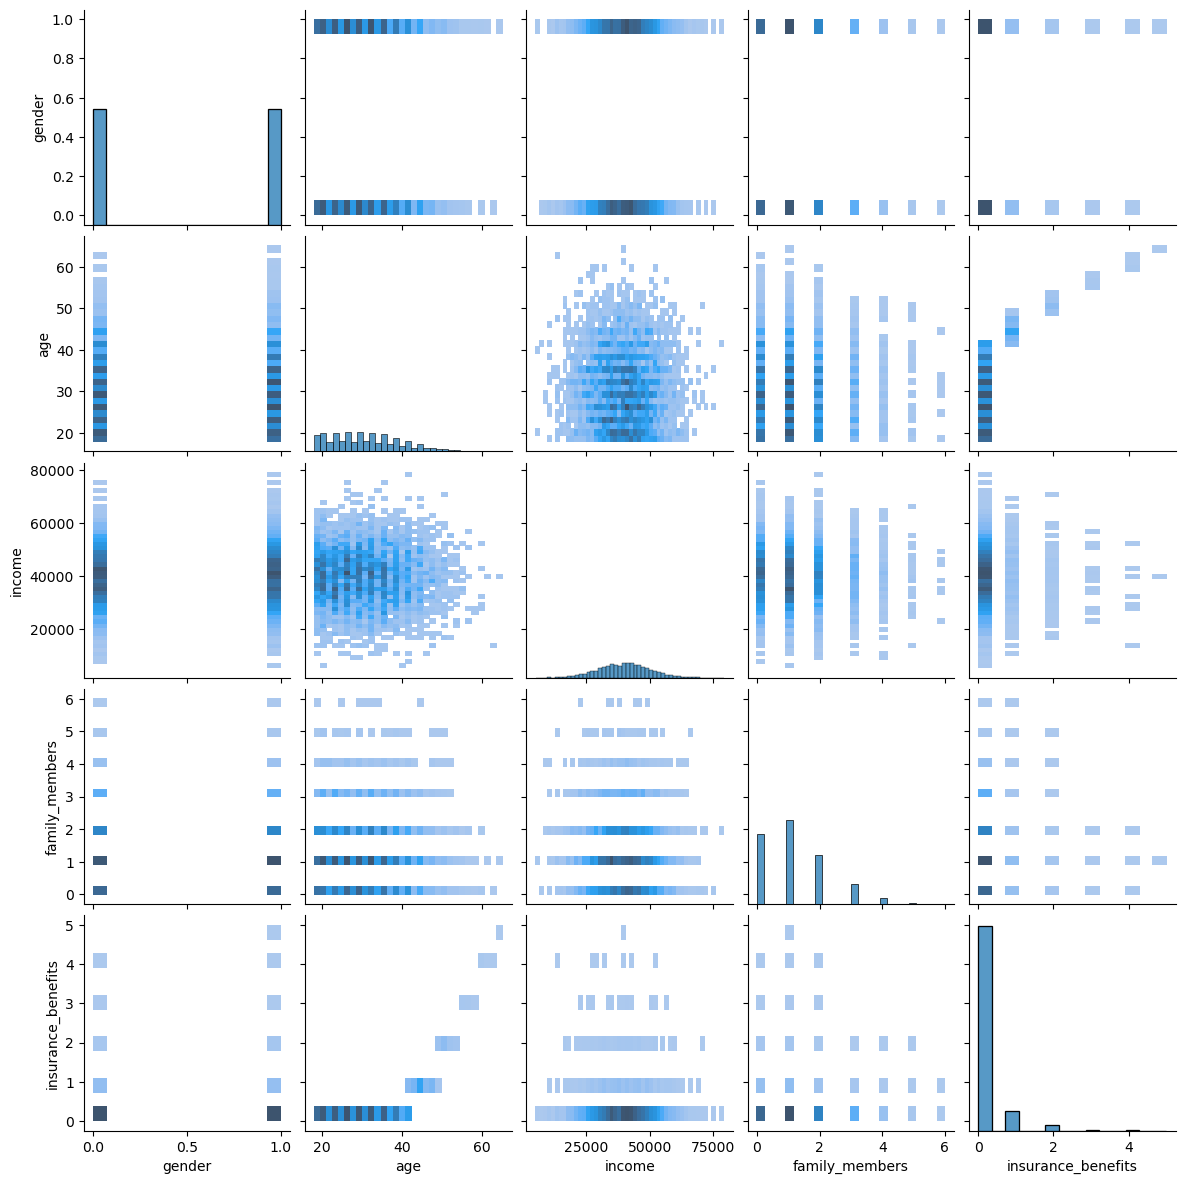

In [13]:
g = sns.pairplot(df, kind='hist')
g.fig.set_size_inches(12, 12)

Ok, é um pouco difícil identificar grupos óbvios (clusters), pois é difícil combinar várias variáveis simultaneamente (para analisar distribuições multivariadas). É aí que Álgebra Linear e Aprendizado de Máquina podem ser bastante úteis.

<div class="alert alert-block alert-info">
<b>Resposta do Aluno:
Eu concordo que é difícil identificar grupos óbivos (clusters) apenas observando os gráficos de pares. Ainda assim, eu diria que já ficou claro que os clientes que mais receberam pagamentos de seguro foram aqueles com mais de 40 anos de idade, uma vez que não parecem existir números de pares significativos para qualquer idade menor de 40 anos e qualquer número de pagamentos de seguro acima de 0. Esses pares, menos de 40 anos e 1 ou mais pagamentos de seguro, nem sequer aparecem nos gráficos de pares.</b> <a class="tocSkip"></a>
</div>

# Tarefa 1. Clientes Similares

Na linguagem de AM, é necessário desenvolver um procedimento que retorne k vizinhos mais próximos (objetos) para um determinado objeto com base na distância entre os objetos.

Você pode querer rever as seguintes lições (capítulo -> lição)
- Distância Entre Vetores -> Distância Euclidiana
- Distância Entre Vetores -> Distância de Manhattan

Para resolver a tarefa, podemos tentar diferentes métricas de distância.

Escreva uma função que retorne k vizinhos mais próximos para um n-ésimo objeto com base em uma métrica de distância especificada. O número de pagamentos de seguro recebidos não deve ser levado em consideração para esta tarefa. 

Você pode usar uma implementação pronta do algoritmo kNN do scikit-learn (verifique [o link](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html#sklearn.neighbors.NearestNeighbors)) ou usar a sua própria.

Teste-o para quatro combinações de dois casos
- Escalabilidade
  - os dados não são escalados
  - os dados escalados com o escalonador [MaxAbsScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MaxAbsScaler.html) 
- Métricas de distância
  - Euclidiana
  - Manhattan

Responda às perguntas:
- Os dados não escalados afetam o algoritmo kNN? Se sim, como isso acontece?
-Quão semelhantes são os resultados usando a métrica de distância de Manhattan (independentemente da escalabilidade)?

In [14]:
feature_names = ['gender', 'age', 'income', 'family_members']

In [15]:
def get_knn(df, n, k, metric):

    """
    Retorna os vizinhos mais próximos de k

    :param df: DataFrame pandas usado para encontrar objetos semelhantes dentro de
    :param n: número do objeto pelo qual os vizinhos mais próximos são procurados
    :param k: o número dos vizinhos mais próximos a serem retornados
    :param metric: nome da métrica de distância
    """

    nbrs = sklearn.neighbors.NearestNeighbors(n_neighbors=k,metric=metric).fit(df[feature_names])# <escreva seu código aqui>
    nbrs_distances, nbrs_indices = nbrs.kneighbors([df.iloc[n][feature_names]], k, return_distance=True)

    df_res = pd.concat([
        df.iloc[nbrs_indices[0]],
        pd.DataFrame(nbrs_distances.T, index=nbrs_indices[0], columns=['distance'])
        ], axis=1)

    return df_res

Escalando os dados

In [16]:
feature_names = ['gender', 'age', 'income', 'family_members']

transformer_mas = sklearn.preprocessing.MaxAbsScaler().fit(df[feature_names].to_numpy())

df_scaled = df.copy()
df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())

In [17]:
df_scaled.sample(5,random_state=12345)

,gender,age,income,family_members,insurance_benefits
3183,0.0,0.507692,0.493671,0.666667,0
1071,0.0,0.769231,0.545570,0.333333,2
2640,1.0,0.600000,0.532911,0.000000,0
2282,0.0,0.307692,0.440506,0.000000,0
1595,0.0,0.630769,0.506329,0.666667,0


Agora, vamos obter registros semelhantes para um determinado registro para cada combinação

In [18]:
n = 0 # Registro escolhido para comparações. Usando o primeiro registro
k = 10 # 10 vizinhos. Número escolhido para termos uma boa quantidade de comparações apra analisar

df_neighbors_euclidean = get_knn(df,n,k,"euclidean")
df_neighbors_manhattan = get_knn(df,n,k,"manhattan")
df_scaled_neighbors_euclidean = get_knn(df_scaled,n,k,"euclidean")
df_scaled_neighbors_manhattan = get_knn(df_scaled,n,k,"manhattan")

In [19]:
display(df_neighbors_euclidean)
display(df_scaled_neighbors_euclidean)

,gender,age,income,family_members,insurance_benefits,distance
0,1,41,49600.0,1,0,0.000000
2022,1,41,49600.0,0,0,1.000000
1225,0,42,49600.0,0,1,1.732051
4031,1,44,49600.0,2,1,3.162278
3424,0,38,49600.0,0,0,3.316625
815,1,37,49600.0,2,0,4.123106
4661,0,45,49600.0,0,1,4.242641
2125,0,37,49600.0,2,0,4.242641
2349,1,46,49600.0,2,1,5.099020
3900,1,36,49600.0,0,0,5.099020


,gender,age,income,family_members,insurance_benefits,distance
0,1.0,0.630769,0.627848,0.166667,0,0.000000
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.017754
4869,1.0,0.646154,0.637975,0.166667,1,0.018418
3275,1.0,0.646154,0.651899,0.166667,1,0.028550
1567,1.0,0.615385,0.602532,0.166667,0,0.029624
2103,1.0,0.630769,0.596203,0.166667,0,0.031646
3365,1.0,0.630769,0.596203,0.166667,0,0.031646
124,1.0,0.661538,0.635443,0.166667,1,0.031693
3636,1.0,0.615385,0.600000,0.166667,0,0.031815


In [20]:
display(df_neighbors_manhattan)
display(df_scaled_neighbors_manhattan)

,gender,age,income,family_members,insurance_benefits,distance
0,1,41,49600.0,1,0,0.0
2022,1,41,49600.0,0,0,1.0
1225,0,42,49600.0,0,1,3.0
4031,1,44,49600.0,2,1,4.0
815,1,37,49600.0,2,0,5.0
3424,0,38,49600.0,0,0,5.0
2125,0,37,49600.0,2,0,6.0
3900,1,36,49600.0,0,0,6.0
2349,1,46,49600.0,2,1,6.0
4661,0,45,49600.0,0,1,6.0


,gender,age,income,family_members,insurance_benefits,distance
0,1.0,0.630769,0.627848,0.166667,0,0.000000
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.024245
4869,1.0,0.646154,0.637975,0.166667,1,0.025511
3365,1.0,0.630769,0.596203,0.166667,0,0.031646
2103,1.0,0.630769,0.596203,0.166667,0,0.031646
124,1.0,0.661538,0.635443,0.166667,1,0.038364
4305,1.0,0.630769,0.588608,0.166667,0,0.039241
3275,1.0,0.646154,0.651899,0.166667,1,0.039435
1567,1.0,0.615385,0.602532,0.166667,0,0.040701


Respostas para as perguntas

**Os dados não escalados afetam o algoritmo kNN? Se sim, como isso acontece?** 

Coloque sua resposta aqui.

#### RESPOTA DO ALUNO:

Sim! Escalar os dados mudam os resultados do algoritmo kNN. Os dados não escalados, independente da métrica utilizada, retornam dados vizinhos que são baseados primeiramente na característica "income" (salário). Todos os dados vizinhos tem exatamente o mesmo salário mas as outras características não são tão próximas. Isso é um resultado das diferentes escalas das características. Por exemplo, gender (gênero) é discreta e binária, só tem os valores 0 e 1. Então uma distância de um cliente com valor 0 para um cliente com valor 1 é apenas 1 de distância nessa característica. Por outro lado, mesmo uma mudança modesta de 100 dólares a mais no salário de um cliente para outro já resulta em uma distância de 100. Isso significa que a caracterísica income acaba dominando a distância por ter um peso muito maior no resultado.

Já os dados escalados colocam todas as características aproximadamente na mesma escala de 0 a 1 (isso é o que faz MaxAbsScaler). Isso significa que as caractereísticas vão ter contribuições muito mais equilibradas. No examplo, todas as observações vizinhas tem o mesmo valor em gênero e membros da família, mas não de idade e salário. Ainda assim, as idades e salários são próximas os suficiente para considerarmos esses valores próximos ou vizinhos.



In [21]:
euclidean_comp = df_neighbors_euclidean[['distance']].copy()
euclidean_comp['rank_euclidean'] = range(1, len(euclidean_comp) + 1)
euclidean_comp = euclidean_comp.rename(columns={'distance': 'distance_euclidean'})

manhattan_comp = df_neighbors_manhattan[['distance']].copy()
manhattan_comp['rank_manhattan'] = range(1, len(manhattan_comp) + 1)
manhattan_comp = manhattan_comp.rename(columns={'distance': 'distance_manhattan'})

compare = euclidean_comp.merge(manhattan_comp,left_index=True,right_index=True,how="outer")

In [22]:
compare

,distance_euclidean,rank_euclidean,distance_manhattan,rank_manhattan
0,0.000000,1,0.0,1
815,4.123106,6,5.0,5
1225,1.732051,3,3.0,3
2022,1.000000,2,1.0,2
2125,4.242641,8,6.0,7
2349,5.099020,9,6.0,9
3424,3.316625,5,5.0,6
3900,5.099020,10,6.0,8
4031,3.162278,4,4.0,4
4661,4.242641,7,6.0,10


In [23]:
euclidean_scaled_comp = df_scaled_neighbors_euclidean[['distance']].copy()
euclidean_scaled_comp['rank_euclidean'] = range(1, len(euclidean_scaled_comp) + 1)
euclidean_scaled_comp = euclidean_scaled_comp.rename(columns={'distance': 'distance_euclidean'})

manhattan_scaled_comp = df_scaled_neighbors_manhattan[['distance']].copy()
manhattan_scaled_comp['rank_manhattan'] = range(1, len(manhattan_scaled_comp) + 1)
manhattan_scaled_comp = manhattan_scaled_comp.rename(columns={'distance': 'distance_manhattan'})

compare_scaled = euclidean_scaled_comp.merge(manhattan_scaled_comp,left_index=True,right_index=True,how="outer")

In [24]:
compare_scaled

,distance_euclidean,rank_euclidean,distance_manhattan,rank_manhattan
0,0.000000,1.0,0.000000,1.0
124,0.031693,9.0,0.038364,7.0
133,0.017754,3.0,0.024245,3.0
1567,0.029624,6.0,0.040701,10.0
2103,0.031646,7.0,0.031646,6.0
2689,0.006329,2.0,0.006329,2.0
3275,0.028550,5.0,0.039435,9.0
3365,0.031646,8.0,0.031646,5.0
3636,0.031815,10.0,NaN,NaN
4305,NaN,NaN,0.039241,8.0


**Quão semelhantes são os resultados usando a métrica de distância de Manhattan (independentemente da escalabilidade)?** 

Coloque sua resposta aqui.

#### RESPOTA DO ALUNO:

Os resultados que usam a métrica de distância Manhattan são muito semelhantes aos resultados usando a distância Euclidiana. Para dados não escalados, todas as 10 observações aparecem nos resultados de ambas métricas, com pequenas diferenças nas ordens e valores de distância. Já para dados escalados, quase todas as observações vizinhas aparecem em ambas as métricas, com apenas algumas diferenças na ordem em que são retornados. Isso ocorre porque as duas fórmulas das métricas procuram observações próximas, mas utilizam fórmulas/métricas diferentes para calcular a distância o que resulta em pequenas diferenças nas ordens e nas distâncias resultadas.


# Tarefa 2. É provável que o cliente receba um pagamento do seguro?

Em termos de aprendizado de máquina, podemos olhar para isso como uma tarefa de classificação binária.

Com os pagamentos de seguro sendo mais do que zero como objetivo, avalie se a abordagem da classificação kNN pode ser melhor do que um modelo dummy.

Instruções:
- Construa um classificador baseado em kNN e meça sua qualidade com a métrica F1 para k=1..10 tanto para os dados originais quanto para os escalados. Seria interessante ver como k pode influenciar a métrica de avaliação e se a escalabilidade dos dados faz alguma diferença. Você pode usar uma implementação pronta do algoritmo de classificação kNN do scikit-learn (verifique [o link](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)) ou usar a sua própria.
- Construa o modelo dummy, que é aleatório para este caso. Deve retornar com alguma probabilidade o valor "1". LVamos testar o modelo com quatro valores de probabilidade: 0, a probabilidade de fazer qualquer pagamento de seguro, 0,5, 1.

A probabilidade de fazer qualquer pagamento de seguro pode ser definida como

$$
P\{\text{pagamento de seguro recebido}= número de clientes que receberam qualquer pagamento de seguro}}{\text{número total de clientes}}.
$$

Divida os dados inteiros na proporção 70:30 para as partes de treinamento/teste.

$$
P(\text{pagamento de seguro recebido})
=
\frac{\text{número de clientes que receberam qualquer pagamento de seguro}}
{\text{número total de clientes}}
$$

In [25]:
# calcule a meta

#<seu código aqui>


# criando objetivo/meta para dados não escalados
target_name = "insurance_benefits_received"
df[target_name] = (df['insurance_benefits']>0).astype(int)

In [26]:
# verifique o desequilíbrio de classe com value_counts()

# <seu código aqui>

df[target_name].value_counts()

0    4436
1     564
Name: insurance_benefits_received, dtype: int64

In [27]:
def eval_classifier(y_true, y_pred):

    f1_score = sklearn.metrics.f1_score(y_true, y_pred)
    print(f'F1: {f1_score:.2f}')

# se você tiver um problema com a linha a seguir, reinicie o kernel e execute o caderno novamente
    cm = sklearn.metrics.confusion_matrix(y_true, y_pred, normalize='all')
    print('Matriz de Confusão')
    print(cm)

In [28]:
# gerando saída de um modelo aleatório

def rnd_model_predict(P, size, seed=42):

    rng = np.random.default_rng(seed=seed)
    return rng.binomial(n=1, p=P, size=size)

In [29]:
for P in [0, df[target_name].sum() / len(df), 0.5, 1]:

    print(f'A probabilidade: {P:.2f}')
    # <seu código aqui>

    y_pred_rnd = rnd_model_predict(P,size=df[target_name].size)
    eval_classifier(df[target_name], y_pred_rnd)

    print()

A probabilidade: 0.00
F1: 0.00
Matriz de Confusão
[[0.8872 0.    ]
 [0.1128 0.    ]]

A probabilidade: 0.11
F1: 0.12
Matriz de Confusão
[[0.7914 0.0958]
 [0.0994 0.0134]]

A probabilidade: 0.50
F1: 0.20
Matriz de Confusão
[[0.456  0.4312]
 [0.053  0.0598]]

A probabilidade: 1.00
F1: 0.20
Matriz de Confusão
[[0.     0.8872]
 [0.     0.1128]]



In [30]:
# criando objetivo para dados escalados
df_scaled[target_name] = (df_scaled['insurance_benefits']>0).astype(int)

# dividindo datasets entre treinamento e validação na proporção 70:30
df_train, df_valid = train_test_split(df,test_size=0.3,random_state=42)
df_train_scaled, df_valid_scaled = train_test_split(df_scaled, test_size=0.3,random_state=42)

# dividindo dataset entre características e objetivo
features_train = df_train.loc[:,feature_names]
features_valid = df_valid.loc[:,feature_names]
target_train = df_train[target_name]
target_valid = df_valid[target_name]

# dividindo dataset escalado entre características e objetivo
features_train_scaled = df_train_scaled.loc[:,feature_names]
features_valid_scaled = df_valid_scaled.loc[:,feature_names]
target_train_scaled = df_train_scaled[target_name]
target_valid_scaled = df_valid_scaled[target_name]

De acordo com a documentação da implementação do KNeighborsClassifier de Scikit-Learn, podemos passar o hiperparâmetro n_neighbors para usar como valor padrão para qualquer função que use o valor k (número de vizinhos). Dessa forma, o modelo irá usar o valor de n_neighbors para classificar suas predições ao chamarmos predict().

Alternativamente, poderíamos passar qualquer valor para n_neighbors, usar a função kneighbors de KNeighborsClassifier para receber a lista de vizinhos e usar essa única lista para criar predições para cada valor de k. Essa alternativa evitaria a recriação do objeto de modelo knn_classifier, mas o código seria mais longo e teríamos que lidar com algumas complicações (como a possiblidade de empates para valores pares de k). Escolhi criar um classificador para cada valor de k.

In [31]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        category=FutureWarning,
        message="Unlike other reduction functions.*"
    )

    df_scores = []

    for k in range(1,11):
        knn_classifier = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k)
        knn_classifier.fit(features_train, target_train)
        predict_valid = knn_classifier.predict(features_valid)

        print("Dados NÃO escalados"+ "\n" + "k =",k)
        eval_classifier(target_valid, predict_valid)
        df_scores.append([0,k,sklearn.metrics.f1_score(target_valid, predict_valid)])



Dados NÃO escalados
k = 1
F1: 0.65
Matriz de Confusão
[[0.87466667 0.018     ]
 [0.04666667 0.06066667]]
Dados NÃO escalados
k = 2
F1: 0.38
Matriz de Confusão
[[0.89066667 0.002     ]
 [0.082      0.02533333]]
Dados NÃO escalados
k = 3
F1: 0.39
Matriz de Confusão
[[0.88333333 0.00933333]
 [0.07933333 0.028     ]]
Dados NÃO escalados
k = 4
F1: 0.16
Matriz de Confusão
[[0.88933333 0.00333333]
 [0.098      0.00933333]]
Dados NÃO escalados
k = 5
F1: 0.17
Matriz de Confusão
[[0.88333333 0.00933333]
 [0.09666667 0.01066667]]
Dados NÃO escalados
k = 6
F1: 0.09
Matriz de Confusão
[[8.92000000e-01 6.66666667e-04]
 [1.02000000e-01 5.33333333e-03]]
Dados NÃO escalados
k = 7
F1: 0.12
Matriz de Confusão
[[0.89133333 0.00133333]
 [0.10066667 0.00666667]]
Dados NÃO escalados
k = 8
F1: 0.02
Matriz de Confusão
[[0.89266667 0.        ]
 [0.106      0.00133333]]
Dados NÃO escalados
k = 9
F1: 0.04
Matriz de Confusão
[[0.89266667 0.        ]
 [0.10533333 0.002     ]]
Dados NÃO escalados
k = 10
F1: 0.04
Mat

In [32]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        category=FutureWarning,
        message="Unlike other reduction functions.*"
    )

    for k in range(1,11):
        knn_classifier = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k)
        knn_classifier.fit(features_train_scaled, target_train_scaled)
        predict_valid_scaled = knn_classifier.predict(features_valid_scaled)

        print("Dados ESCALADOS"+ "\n" + "k =",k)
        eval_classifier(target_valid_scaled, predict_valid_scaled)
        df_scores.append([1,k,sklearn.metrics.f1_score(target_valid_scaled, predict_valid_scaled)])

    df_scores = pd.DataFrame(data=df_scores,columns=["scaled","k","f1_score"])



Dados ESCALADOS
k = 1
F1: 0.93
Matriz de Confusão
[[0.888      0.00466667]
 [0.00933333 0.098     ]]
Dados ESCALADOS
k = 2
F1: 0.92
Matriz de Confusão
[[0.89066667 0.002     ]
 [0.01466667 0.09266667]]
Dados ESCALADOS
k = 3
F1: 0.94
Matriz de Confusão
[[0.88933333 0.00333333]
 [0.00933333 0.098     ]]
Dados ESCALADOS
k = 4
F1: 0.91
Matriz de Confusão
[[0.89133333 0.00133333]
 [0.016      0.09133333]]
Dados ESCALADOS
k = 5
F1: 0.94
Matriz de Confusão
[[0.88933333 0.00333333]
 [0.01       0.09733333]]
Dados ESCALADOS
k = 6
F1: 0.91
Matriz de Confusão
[[0.89133333 0.00133333]
 [0.01666667 0.09066667]]
Dados ESCALADOS
k = 7
F1: 0.93
Matriz de Confusão
[[0.89       0.00266667]
 [0.012      0.09533333]]
Dados ESCALADOS
k = 8
F1: 0.91
Matriz de Confusão
[[8.92000000e-01 6.66666667e-04]
 [1.66666667e-02 9.06666667e-02]]
Dados ESCALADOS
k = 9
F1: 0.93
Matriz de Confusão
[[0.89133333 0.00133333]
 [0.01266667 0.09466667]]
Dados ESCALADOS
k = 10
F1: 0.91
Matriz de Confusão
[[8.92000000e-01 6.66666

In [33]:
display(df_scores)

,scaled,k,f1_score
0,0,1,0.652330
1,0,2,0.376238
2,0,3,0.387097
3,0,4,0.155556
4,0,5,0.167539
5,0,6,0.094118
6,0,7,0.115607
7,0,8,0.024540
8,0,9,0.036585
9,0,10,0.036585


Analisando os resultados, o modelo dummy têm seu melhor desempenho quando a probabilidade usada na distribuição que constrói esse modelo é igual a probabilidade de um cliente receber prêmios do seguro se nos basearmos puramente nos dados que temos como referência. Em outras palavras, se definirmos a probabilidade como # de clientes que receberam pagamentos de seguro / # de clientes, o modelo que prevê a classe positiva com essa probabilidade tem o melhor desempenho entre os modelos dummy. 

Os modelos reais tem uma performance clara: o modelo treinando em dados não escalados não consegue passar de um F1 Score de 0.65 que só é atingido quando k = 1. Quanto mais k aumenta, mais o F1 Score diminui. Por outro lado, os modelos treinados com dados escalados tem melhores F1 Scores e também quantidade de verdadeiros positivos. A única grande diferença entre esses modelos é que quando k é um número par, a performance diminui. Isso pode ser possívelmente devido a possibilidade de existirem empates quando usamos valores pares para k. Isso significa que o F1 Score tem a tendência a diminuir, embora não o faça linearmente e proporcionalmente ao aumento de vizinhos, mas também o número de verdadeiros positivos tende a diminuir e o número de falso negativos a aumentar. Isso significa que não adianta ficarmos apenas aumentando o valor de k, principalmente para um problema como esse que tem a classe positiva como minoria. Aumentar o número de k significa aumentar a probabiliadde dos vizinhos conterem muitos valores da classe negativa, até chegar o ponto em que os vizinhos da classe minoritária estão em maior número mesmo que suas distâncias não necessariamente os toraniram vizinhos próximos. Usar o hiperparâmetro weights='distance' pode ajudar!

TESTE ADICIONAL

Testando o hiperparâmetro weights='distance' - levando em consideração a distância de cada vizinho para contribuir um peso proporcional ao classificar as predições.

In [34]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        category=FutureWarning,
        message="Unlike other reduction functions.*"
    )

    for k in range(1,11):
        knn_classifier = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k,weights='distance')
        knn_classifier.fit(features_train_scaled, target_train_scaled)
        predict_valid_scaled = knn_classifier.predict(features_valid_scaled)

        print("Dados ESCALADOS"+ "\n" + "k =",k)
        eval_classifier(target_valid_scaled, predict_valid_scaled)



Dados ESCALADOS
k = 1
F1: 0.93
Matriz de Confusão
[[0.888      0.00466667]
 [0.00933333 0.098     ]]
Dados ESCALADOS
k = 2
F1: 0.93
Matriz de Confusão
[[0.888      0.00466667]
 [0.00933333 0.098     ]]
Dados ESCALADOS
k = 3
F1: 0.94
Matriz de Confusão
[[0.88866667 0.004     ]
 [0.00933333 0.098     ]]
Dados ESCALADOS
k = 4
F1: 0.95
Matriz de Confusão
[[0.89       0.00266667]
 [0.00866667 0.09866667]]
Dados ESCALADOS
k = 5
F1: 0.95
Matriz de Confusão
[[0.89066667 0.002     ]
 [0.00933333 0.098     ]]
Dados ESCALADOS
k = 6
F1: 0.94
Matriz de Confusão
[[0.89       0.00266667]
 [0.01       0.09733333]]
Dados ESCALADOS
k = 7
F1: 0.94
Matriz de Confusão
[[0.89066667 0.002     ]
 [0.01       0.09733333]]
Dados ESCALADOS
k = 8
F1: 0.95
Matriz de Confusão
[[0.89066667 0.002     ]
 [0.00866667 0.09866667]]
Dados ESCALADOS
k = 9
F1: 0.95
Matriz de Confusão
[[0.89066667 0.002     ]
 [0.00866667 0.09866667]]
Dados ESCALADOS
k = 10
F1: 0.95
Matriz de Confusão
[[0.89066667 0.002     ]
 [0.00866667 0.

# Tarefa 3. Regressão (com Regressão Linear)

Com os pagamentos de seguro como objetivo, avalie qual seria o REQM para um modelo de Regressão Linear.

Construa sua própria implementação de Regressão Linear. Para isso, lembre-se de como a solução da tarefa de regressão linear é formulada em termos de Álgebra linear. Verifique o REQM para os dados originais e os escalados. Você pode ver alguma diferença no REQM entre esses dois casos?

Vamos denotar
- $X$ — matriz de características, cada linha é um caso, cada coluna é uma característica, a primeira coluna consiste em unidades
- $y$ — objetivo (um vetor)
- $\hat{y}$ — objetivo estimado (um vetor)
- $w$ — vetor de peso

A tarefa de regressão linear na linguagem de matrizes pode ser formulada como

$$
y = Xw
$$

O objetivo do treinamento, então, é encontrar os $w$ que minimizaria a distância L2 (EQM) entre $Xw$ e $y$:

$$
\min_w d_2(Xw, y) \quad \text{or} \quad \min_w \text{MSE}(Xw, y)
$$

Parece que há uma solução analítica para a questão acima:

$$
w = (X^T X)^{-1} X^T y
$$

A fórmula acima pode ser usada para encontrar os pesos $w$ e o último pode ser usado para calcular valores preditos

$$
\hat{y} = X_{val}w
$$

Divida todos os dados na proporção 70:30 para as partes de treinamento/validação. Use a métrica REQM para a avaliação do modelo.

In [35]:
class MyLinearRegression:

    def __init__(self):

        self.weights = None

    def fit(self, X, y):

        # somando as unidades
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)
        self.weights = np.linalg.inv(X2.T @ X2) @ (X2.T @ y)# <seu código aqui>

    def predict(self, X):

        # somando as unidades
        X2 = np.append(np.ones([len(X), 1]), X, axis=1)# <seu código aqui>
        y_pred = X2.dot(self.weights)# <seu código aqui>

        return y_pred

In [36]:
def eval_regressor(y_true, y_pred):

    rmse = math.sqrt(sklearn.metrics.mean_squared_error(y_true, y_pred))
    print(f'REQM: {rmse:.2f}')

    r2_score = math.sqrt(sklearn.metrics.r2_score(y_true, y_pred))
    print(f'R2: {r2_score:.2f}')

In [37]:
X = df[['age', 'gender', 'income', 'family_members']].to_numpy()
y = df['insurance_benefits'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=12345)

lr = MyLinearRegression()

lr.fit(X_train, y_train)
print(lr.weights)

y_test_pred = lr.predict(X_test)
eval_regressor(y_test, y_test_pred)

[-9.43539012e-01  3.57495491e-02  1.64272726e-02 -2.60743659e-07
 -1.16902127e-02]
REQM: 0.34
R2: 0.66


In [38]:
X = df_scaled[['age', 'gender', 'income', 'family_members']].to_numpy()
y = df_scaled['insurance_benefits'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=12345)

lr = MyLinearRegression()

lr.fit(X_train, y_train)
print(lr.weights)

y_test_pred = lr.predict(X_test)
eval_regressor(y_test, y_test_pred)

[-0.94353901  2.32372069  0.01642727 -0.02059875 -0.07014128]
REQM: 0.34
R2: 0.66


Os valores de R2 Score e REQM são idênticos para os dados originis e escalados. A escala altera os coeficientes (pesos), mas não altera as previsões (desde que a transformação de ofuscação seja invertível).

# Tarefa 4. Ofuscando dados

É melhor ofuscar os dados multiplicando as características numéricas (lembre-se, elas podem ser vistos como a matriz $X$) por uma matriz invertível $P$. 

$$
X' = X \times P
$$

Tente fazer isso e verifique como os valores das características ficarão após a transformação. Aliás, a invertibilidade é importante aqui, portanto, certifique-se de que $P$ seja realmente invertível.

Você pode querer revisar a lição 'Matrizes e Operações com Matrizes -> Multiplicação de Matrizes' para relembrar a regra de multiplicação de matrizes e sua implementação com NumPy.

In [39]:
personal_info_column_list = ['gender', 'age', 'income', 'family_members']
df_pn = df[personal_info_column_list]

In [40]:
X = df_pn.to_numpy()

Gerando uma matriz $P$ aleatória.

In [41]:
rng = np.random.default_rng(seed=42)
P = rng.random(size=(X.shape[1], X.shape[1]))

Verificando se a matriz $P$ é invertível

In [42]:
P_inv = np.linalg.inv(P)

Você consegue adivinhar a idade ou a renda dos clientes após a transformação?

In [43]:
X_prime = X @ P

In [44]:
display(X_prime)

array([[ 6359.71527314, 22380.40467609, 18424.09074184, 46000.69669016],
       [ 4873.29406479, 17160.36702982, 14125.78076133, 35253.45577301],
       [ 2693.11742928,  9486.397744  ,  7808.83156024, 19484.86063067],
       ...,
       [ 4346.2234249 , 15289.24126492, 12586.16264392, 31433.50888552],
       [ 4194.09324155, 14751.9910242 , 12144.02930637, 30323.88763426],
       [ 5205.46827354, 18314.24814446, 15077.01370762, 37649.59295455]])

Não é possível diretamente adivinhar a idade ou renda dos clientes após a transformação sem ter acesso a matrix usada para a ofuscação (e seu inverso). Embora os valores ainda sejam proporcionais entre si, os valores exatos não são acessíveis, uma vez que cada valor é uma soma com peso estipulado pela matrix P.

Você pode recuperar os dados originais de $X′$ se souber $P$? Tente verificar isso com cálculos movendo $P$ do lado direito da fórmula acima para o esquerdo. As regras da multiplicação de matrizes são realmente úteis aqui

In [45]:
X_recovered = X_prime @ P_inv

In [46]:
display(X_recovered)

array([[ 1.00000000e+00,  4.10000000e+01,  4.96000000e+04,
         1.00000000e+00],
       [ 1.67952800e-12,  4.60000000e+01,  3.80000000e+04,
         1.00000000e+00],
       [-6.23021448e-13,  2.90000000e+01,  2.10000000e+04,
        -2.03032656e-13],
       ...,
       [ 1.57996161e-12,  2.00000000e+01,  3.39000000e+04,
         2.00000000e+00],
       [ 1.00000000e+00,  2.20000000e+01,  3.27000000e+04,
         3.00000000e+00],
       [ 1.00000000e+00,  2.80000000e+01,  4.06000000e+04,
         1.00000000e+00]])

Em um primeiro momento, parece que os dados não são os mesmos, mas o fato de Python estar retornando Notação Científica me faz acreditar que o que aconteceu é apenas o resultado de cálculos com Floating Points, como o que acontece ao adicionar 0.1 e 0.7 e receber algo como 0.799999999999 ao invés de 0.8. Isso deve ter acontecido devido a conversão do DataFrame para NumPy.ndarray e também ao executar a multiplicações de matrizes, que passaram a usar Floats ao invés de ints como originalmente

In [47]:
# Exemplo

0.1 + 0.7

0.7999999999999999

In [48]:
# Descobri essa função para testar se as matrizes são equivalentes
# Se retornar True, as matrizes são as mesmas

np.allclose(X,X_recovered)

True

In [49]:
# Testando a conversão dos valores para integers
# Descobri que arredondar usando .astype(int) diretamente sem usar np.rint() retorna valores incorretos (arredondamentos para baixo muitas vezes)

X_recovered_rounded = np.rint(X_recovered).astype(int)
display(X_recovered_rounded)

array([[    1,    41, 49600,     1],
       [    0,    46, 38000,     1],
       [    0,    29, 21000,     0],
       ...,
       [    0,    20, 33900,     2],
       [    1,    22, 32700,     3],
       [    1,    28, 40600,     1]])

Essa matriz parece muito mais com os dados originais!

Imprima todos os três casos para alguns clientes
- Os dados originais
- O transformado
- O invertido (recuperado)

In [50]:
indices = rng.choice(len(X), size=10,replace=False)

print(X[indices])


[[0.00e+00 4.60e+01 3.83e+04 0.00e+00]
 [1.00e+00 3.60e+01 5.74e+04 1.00e+00]
 [1.00e+00 4.10e+01 5.19e+04 0.00e+00]
 [0.00e+00 1.90e+01 3.68e+04 0.00e+00]
 [1.00e+00 2.40e+01 3.70e+04 2.00e+00]
 [0.00e+00 2.80e+01 4.92e+04 0.00e+00]
 [1.00e+00 1.80e+01 4.15e+04 3.00e+00]
 [1.00e+00 2.20e+01 5.05e+04 2.00e+00]
 [0.00e+00 4.10e+01 3.84e+04 1.00e+00]
 [0.00e+00 2.40e+01 1.87e+04 1.00e+00]]


In [51]:
print(X_prime[indices])

[[ 4911.08428948 17294.66004958 14236.5767544  35531.25803094]
 [ 7358.53072127 25888.53687992 21312.50963234 53225.53328165]
 [ 6653.73276317 23415.46957164 19276.48278337 48132.02892579]
 [ 4716.37105207 16592.73933924 13659.8289461  34119.88681143]
 [ 4744.52635163 16689.77904024 13739.53967577 34310.3219762 ]
 [ 6305.82769338 22186.30557031 18264.5747039  45618.8472519 ]
 [ 5321.11649971 18711.48478828 15404.0073608  38476.27527891]
 [ 6473.87203806 22768.03795713 18743.79072351 46820.07719704]
 [ 4924.06863112 17335.64329322 14270.29427251 35620.23144702]
 [ 2398.6290525   8446.4547367   6952.6338202  17349.59807352]]


In [52]:
print(X_recovered[indices])

[[ 5.19281651e-13  4.60000000e+01  3.83000000e+04 -1.27963915e-12]
 [ 1.00000000e+00  3.60000000e+01  5.74000000e+04  1.00000000e+00]
 [ 1.00000000e+00  4.10000000e+01  5.19000000e+04  3.37102732e-12]
 [ 2.57770916e-12  1.90000000e+01  3.68000000e+04 -3.64555968e-12]
 [ 1.00000000e+00  2.40000000e+01  3.70000000e+04  2.00000000e+00]
 [ 3.23584772e-12  2.80000000e+01  4.92000000e+04  1.31513680e-12]
 [ 1.00000000e+00  1.80000000e+01  4.15000000e+04  3.00000000e+00]
 [ 1.00000000e+00  2.20000000e+01  5.05000000e+04  2.00000000e+00]
 [ 1.13675495e-12  4.10000000e+01  3.84000000e+04  1.00000000e+00]
 [-6.41688991e-13  2.40000000e+01  1.87000000e+04  1.00000000e+00]]


In [53]:
X_rounded = np.rint(X).astype(int)
display(X_rounded[indices])
display(X_recovered_rounded[indices])

array([[    0,    46, 38300,     0],
       [    1,    36, 57400,     1],
       [    1,    41, 51900,     0],
       [    0,    19, 36800,     0],
       [    1,    24, 37000,     2],
       [    0,    28, 49200,     0],
       [    1,    18, 41500,     3],
       [    1,    22, 50500,     2],
       [    0,    41, 38400,     1],
       [    0,    24, 18700,     1]])

array([[    0,    46, 38300,     0],
       [    1,    36, 57400,     1],
       [    1,    41, 51900,     0],
       [    0,    19, 36800,     0],
       [    1,    24, 37000,     2],
       [    0,    28, 49200,     0],
       [    1,    18, 41500,     3],
       [    1,    22, 50500,     2],
       [    0,    41, 38400,     1],
       [    0,    24, 18700,     1]])

Você provavelmente pode ver que alguns valores não são exatamente iguais aos dos dados originais. Qual pode ser a razão disso?

A principal razão é o uso de floats ao converter de DataFrame para NumPy.ndarray. Cálculos de floating points tem peculiaridades em computadores e calculadoras devido ao uso de linguagem binária que não representa números decimais da mesma maneira que estamos acostumados em base 10. Em resumo, os valores precisam ter algum tipo de precisão, isso é, precisam parar em alguma casa após a vírgula. Devido a isso, algumas convenções são seguidas que resultam em valores. Como mostrei acima, se fizermos a conversão de volta para int da maneira correta, podemos recuperar os dados exatos e idênticos tanto para a matriz original criada a partir do DataFrame de dados originais quanto para a matriz de dados recuperados.

## Provas de que a ofuscação de dados pode funcionar com a Regressão Linear

A tarefa de regressão foi resolvida com regressão linear neste projeto. Sua próxima tarefa é provar analiticamente que o método de ofuscação fornecido não afetará a regressão linear em termos de valores preditos, ou seja, seus valores permanecerão os mesmos. Você acredita nisso? Bem, você não precisa acreditar, você deve provar isso!

Assim, os dados são ofuscados e há $X \ P$ em vez de apenas X agora. Consequentemente, existem outros pesos $w_P$ como
$$
w = (X^T X)^{-1} X^T y \quad \Rightarrow \quad w_P = [(XP)^T XP]^{-1} (XP)^T y
$$

Como  $w$ e $w_P$ seriam ligados se você simplificasse a fórmula para $w_P$ acima? 

Quais seriam os valores previstos com $w_P$? 

O que isso significa para a qualidade da regressão linear se você medir com REQM?

Verifique o Apêndice B Propriedades das Matrizes no final do caderno. Existem fórmulas úteis lá!

Nenhum código é necessário nesta seção, apenas explicação analítica!

**Resposta**

O pesos para a matriz ofuscada são o resultado do produto escalar do inverso da matriz de ofuscação com os pesos originais.

$$
w_p = P^{-1}w
$$

E as predições são as mesmas independente de ofuscação (contanto que a matriz de ofuscação seja inversível, então dados não são perdidos):

$$
\hat{y_p} = \hat{y}
$$

As predições são as mesmas independente da ofuscação dos dados! Isso significa que o REQM é o mesmo independente dos dados estarem ofuscados, uma vez que os vetores são idênticos.

Análise abaixo

**Prova analítica**

**Analisando y-hat**

Agora, para os valores previstos usando $$w_p$$, podemos mostra-los da seguinte forma:

$$
\hat{y} = Xw
$$

E sabemos que as predições são o vetor resultante do produto escalar da matrix e o vetor de pesos, então:
$$
\hat{y_p} = X_pw_p
$$

E sabemos que:

$$
X_p = XP
$$

Então:

$$
\hat{y_p} = XPw_p
$$

Logo, usando a definição de w_p:

$$
\hat{y_p} = XPP^{-1}w
$$

Sabemos que:

$$
PP^{-1} = I
$$

Então:

$$
\hat{y_p} = Xw
$$

E isso é igual a fórmula das predições usando a matriz original e os pesos originais, logo:

$$
\hat{y_p} = \hat{y}
$$

As predições são as mesmas independente da ofuscação dos dados!

**Analisando w_p**

Usando as fórmulas do Apêndice B para a derivação abaixo:

Sei que:
$$
w_p = [(XP)^{T}XP]^{-1}(XP)^{T}y
$$
e
$$
w = (X^{T}X)^{-1}X^{T}y
$$

logo

$$
w_p = [(XP)^{T}XP]^{-1}(XP)^{T}y
$$
$$
    = [P^{T}X^{T}XP]^{-1}P^{T}X^{T}y
$$
$$
    = P^{-1} (X^{T}X)^{-1} (P^{T})^{-1}P^{T}X^{T}y
$$

Uma vez que:

$$
(P^{T})^{-1}P^{T} = I
$$

Então:

$$
P^{-1} (X^{T}X)^{-1} (P^{T})^{-1}P^{T}X^{T}y = P^{-1} (X^{T}X)^{-1}X^{T}y
$$

e já que:

$$
w = (X^{T}X)^{-1}X^{T}y
$$

então:

$$
w_p = P^{-1} (X^{T}X)^{-1}X^{T}y = P^{-1}w
$$

Logo, w_p pode ser definida em termos de w da seguinte forma:
$$
w_p = P^{-1}w
$$

Ou seja, 

## Teste de regressão linear com ofuscação de dados

Agora, vamos provar que a Regressão Linear pode funcionar computacionalmente com a transformação de ofuscação escolhida.

Crie um procedimento ou uma classe que execute a Regressão Linear opcionalmente com a ofuscação. Você pode usar uma implementação pronta de Regressão Linear do scikit-learn ou sua própria.

Execute a Regressão Linear para os dados originais e os ofuscados, compare os valores previstos e os valores da métrica $R^2$ do REQM. Há alguma diferença?

**Procedimento**

- Crie uma matriz quadrada $P$ de números aleatórios.
- Verifique se é invertível. Caso contrário, repita o primeiro ponto até obtermos uma matriz invertível.
- <! seu comentário aqui!> Multiplique a matrix X de características para ofuscar pela matriz P para obter $XP$ que é $X^{'}$
- Use $XP$ como a nova matriz de características

In [105]:
class DanLinearRegression:

    def __init__(self):
        self.X = None
        self.weights = None
        self.personal_info_columns = []
        self.obfuscate = False
        self.P = None

    def fit(self, X, y, obfuscate = False, personal_info_columns = None):

        if obfuscate:
            if personal_info_columns:
                self.X, self.P = self.obfuscation(X, personal_info_columns)
                self.personal_info_columns = personal_info_columns
                self.obfuscate = True
            else:
                print("Para ofuscar, é necessário passar os nomes das colunas com valores pessoais")
                return
        else:
            self.X = X
            self.obfuscate = False
            self.P = None
            self.personal_info_columns = []

        X2 = np.append(np.ones([len(X), 1]), self.X, axis=1)
        self.weights = np.linalg.inv(X2.T @ X2) @ (X2.T @ y)

    def obfuscation(self, X, personal_info_columns, P=None):
        X_personal_columns = X.loc[:, personal_info_columns].to_numpy()

        if P is None:
            rng = np.random.default_rng(seed=42)

            # Gerando matrizes até encontrar uma matriz invertível
            # np.linalg.inv() gera LinAlgError se a matriz não for invertível
            while True:
                P = rng.random(size=(X_personal_columns.shape[1], X_personal_columns.shape[1]))

                try:
                    np.linalg.inv(P)
                    break
                except np.linalg.LinAlgError:
                    pass

        X_prime = pd.DataFrame(data=X_personal_columns @ P,columns = personal_info_columns, index = X.index)

        X_obfuscated = X.copy()
        X_obfuscated.loc[:, personal_info_columns] = X_prime.loc[:, personal_info_columns]

        return X_obfuscated, P

    def predict(self, X):
        if self.obfuscate:
            X_predict, _ = self.obfuscation(X, self.personal_info_columns,P=self.P)
        else:
            X_predict = X.copy()

        # somando as unidades
        X2 = np.append(np.ones([len(X_predict), 1]), X_predict, axis=1)
        y_pred = X2.dot(self.weights)

        return y_pred

    def eval_regressor(self, y_true, y_pred):

        rmse = math.sqrt(sklearn.metrics.mean_squared_error(y_true, y_pred))
        print(f'REQM: {rmse:.6f}')

        r2_score = sklearn.metrics.r2_score(y_true, y_pred)
        print(f'R2: {r2_score:.6f}')




In [114]:
target_linear_test = "insurance_benefits"

features_train_dan = features_train.copy()
features_valid_dan = features_valid.copy()
target_train_dan = df_train[target_linear_test]
target_valid_dan = df_valid[target_linear_test]

features_train_obf = df_train.loc[:,feature_names]
features_valid_obf = df_valid.loc[:,feature_names]
target_train_obf = df_train[target_linear_test]
target_valid_obf = df_valid[target_linear_test]


model_original = DanLinearRegression()
model_original.fit(features_train_dan, target_train_dan, obfuscate = False)
predict_valid_dan = model_original.predict(features_valid_dan)
print("Dados Originais:")
model_original.eval_regressor(target_valid_dan,predict_valid_dan)


model_obf = DanLinearRegression()
model_obf.fit(features_train_obf, target_train_obf, obfuscate = True, personal_info_columns=personal_info_column_list)
predict_valid_obf = model_obf.predict(features_valid_obf)
print("Dados Ofuscados:")
model_obf.eval_regressor(target_valid_obf,predict_valid_obf)

Dados Originais:
REQM: 0.363719
R2: 0.422700
Dados Ofuscados:
REQM: 0.363719
R2: 0.422700


In [94]:
target_valid_dan

1501    0
2586    0
2653    0
1055    0
705     1
       ..
3563    0
1538    0
1837    0
2380    0
1912    1
Name: insurance_benefits, Length: 1500, dtype: int64

In [95]:
predict_valid_dan

array([ 0.05001046,  0.16962732,  0.1324396 , ...,  0.13924619,
       -0.30566139,  0.66428927])

In [134]:
test_indices = rng.choice(target_valid_dan.index,size=10,replace=False)
display(target_valid_dan[test_indices])
df_predict_valid_dan = pd.Series(predict_valid_dan,index=target_valid_dan.index)
display(df_predict_valid_dan)

3708    0
463     2
4672    0
809     0
4066    0
2276    0
4711    0
3833    0
1221    0
2174    0
Name: insurance_benefits, dtype: int64

1501    0.050010
2586    0.169627
2653    0.132440
1055    0.100604
705     0.612752
          ...   
3563    0.091157
1538    0.269936
1837    0.139246
2380   -0.305661
1912    0.664289
Length: 1500, dtype: float64

In [145]:
baseline_train = target_train_dan.mean()
baseline_valid = target_valid_dan.mean()
predictions_baseline_train = target_valid_dan * 0 + baseline_train
predictions_baseline_valid = target_valid_dan * 0 + baseline_valid

In [148]:
model_original.eval_regressor(target_valid_dan,predictions_baseline_train)


REQM: 0.478706
R2: -0.000016


In [147]:
print(target_train_dan.mean())
print(target_valid_dan.mean())

print(
    sklearn.metrics.r2_score(
        target_valid_dan,
        predictions_baseline_train
    )
)

0.14857142857142858
0.14666666666666667
-1.58325548993421e-05


Os modelos treinandos com os dados originais produziram previsões equivalentes as previsões dos modelos treinados com os dados ofuscados. Tanto as métricas REQM e R2 são iguais, com talvez pequenas diferenças mínimas devido ao uso de Floating Points. A ofuscação preservou a qualidade do modelo!

# Conclusões

Na Tarefa 1, escalar os dados alterou os vizinhos encontrados porque sem escalonamento a renda domina o cálculo de distâncias. Com escalagem de dados, as outras características passam a contribuir mais equilibradamente para o cálculo de distâncias. As duas métricas, Euclidiana e Manhattan, também resultaram em conjuntos semelhantes de vizinhos com poucas diferenças nas ordens.

Na Tarefa 2, a knn superou os modelos dummy, principalmente com dados escalados. Isso prova que as características tem informações úteis para prever se um cliente receberá pelo menos um pagamento de seguro e que é benéfico para nossos cálculos escalar os dados para que as características possam contribuir (do contrário, apenas renda domina).

Na Tarefa 3, a regressão linear resultou em REQM equivalente para dados originais e dados escalados. Embora os coeficientes (pesos) sejam diferentes para os dados escalados, as previsões não alteram (desde que a escalação seja feita de maneira que informações não sejam perdidas, usando matrizes invertíveis por exemplo).

Na Tarefa 4, os dados foram transformados pela multiplicação de matriz usando uma matriz aleatória P q é invertível. Os dados originais podem ser recuperados se soubermos o inverso de P, com pequenas diferenças devido ao uso de floating points por computadores. Ainda assim, os vetores de predições são idênticos independente de ofuscação de dados e a performance dos modelos treinandos com dados originais ou ofuscados é a mesma também.

# Checklist

Digite 'x' para verificar. Em seguida, pressione Shift + Enter.

- [x]  O Jupyter Notebook está aberto.
- [x]  O código está livre de erros
- [x]  As células são organizadas em ordem de lógica e execução
- [x]  A tarefa 1 foi executada
    - [x]  Existe o procedimento que pode retornar k clientes semelhantes a um determinado cliente
    - [x]  O procedimento é testado para todas as quatro combinações propostas
    - [x]  As perguntas sobre a escala/distâncias são respondidas
- [x]  A tarefa 2 foi executada
    - [x]  O modelo de classificação aleatória é construído e testado para todos os níveis de probabilidade
    - [x]  O modelo de classificação kNN é construído e testado tanto para os dados originais quanto para os escalados, a métrica F1 é calculada.
- [x]  A tarefa 3 foi executada
    - [x]  A solução de regressão linear é implementada com operações matriciais.
    - [x]  O REQM é calculado para a solução implementada.
- [ x  A tarefa 4 foi executada
    - [x]  Os dados são ofuscados com uma matriz P aleatória e invertível
    - [x]  Os dados ofuscados são recuperados, alguns exemplos são impressos
    - [x]  A prova analítica de que a transformação não afeta o REQM é fornecida
    - [x]  A prova computacional de que a transformação não afeta o REQM é fornecida
- [x]  As conclusões foram feitas

# Apêndices

## Apêndice A: Escrevendo Fórmulas em Notebooks Jupyter

Você pode escrever fórmulas em seu Jupyter Notebook em uma linguagem de marcação de texto fornecida por um sistema de publicação de alta qualidade chamado $\LaTeX$ (pronuncia-se "Lah-tech"), e elas se parecerão com fórmulas em livros didáticos.

Para colocar uma fórmula em um texto, coloque o cifrão ($) antes e depois do texto da fórmula, por exemplo $\frac{1}{2} \times \frac{3}{2} = \frac{3}{4}$ or $y = x^2, x \ge 1$.

Se uma fórmula deve estar em seu próprio parágrafo, coloque o cifrão duplo ($$) antes e depois do texto da fórmula, por exemplo

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i.
$$

A linguagem de marcação do [LaTeX](https://en.wikipedia.org/wiki/LaTeX) é muito popular entre as pessoas que usam fórmulas em seus artigos, livros e textos. Pode ser complexo, mas o básico é fácil. Confira esta [folha de dicas](http://tug.ctan.org/info/undergradmath/undergradmath.pdf) de duas páginas  para aprender a compor as fórmulas mais comuns.

## Apêndice B: Propriedades das Matrizes

Matrizes têm muitas propriedades em Álgebra Linear. Algumas delas estão listadas aqui, o que pode ajudar na prova analítica deste projeto.

<table>
<tr>
<td>Distributividade</td><td>$A(B+C)=AB+AC$</td>
</tr>
<tr>
<td>Não-comutatividade</td><td>$AB \neq BA$</td>
</tr>
<tr>
<td>Propriedade associativa da multiplicação</td><td>$(AB)C = A(BC)$</td>
</tr>
<tr>
<td>Propriedade de identidade multiplicativa</td><td>$IA = AI = A$</td>
</tr>
<tr>
<td></td><td>$A^{-1}A = AA^{-1} = I$
</td>
</tr>    
<tr>
<td></td><td>$(AB)^{-1} = B^{-1}A^{-1}$</td>
</tr>    
<tr>
<td>Reversividade da transposição de um produto de matrizes,</td><td>$(AB)^T = B^TA^T$</td>
</tr>    
</table>